# Who goes to the World Championships? Picking a Polish lifter with several metrics

The second analysis in this repository. The first one (`analysis.ipynb`) showed that a single number, even a
good one like IPF GL, cannot say which lifter is better. Here we take an actual selection problem and answer it
with several metrics at once.

**Question.** The Polish federation has one place at the IPF World Classic Championships in the men's 105 kg class.
Which of the active Polish lifters should get it?

**Data:** real Raw (classic) full-power results of Polish lifters since 2023 from [OpenIPF](https://www.openipf.org/),
including individual attempts and bomb-outs. The write-up is in `report/` (Polish) and in the README.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from powerlifting_metrics import LIFTS, attempt_counts, ipf_gl_column, load_country_starts

USE_SAMPLE = True  # bundled sample of Polish starts since 2023; False rebuilds it from the full dataset

SEX = "M"
WEIGHT_CLASS = "105"
ACTIVE_SINCE = "2025-11-01"  # at least one start in the last 12 months
MIN_STARTS = 4               # valid totals since 2023
N_CANDIDATES = 5
FORM_LAST_N = 3              # "current form" = median of the last 3 valid starts

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.precision", 1)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 1. Data

All Raw full-power starts of Polish lifters since 2023, at national (PZKFiTS), European (EPF) and world (IPF) meets.
Unlike in the first analysis we keep **bomb-outs** (a lifter who misses all three attempts in one lift gets no total)
and the **individual attempts**, because both say something about how reliable a lifter is.

In [2]:
starts = load_country_starts("Poland", use_sample=USE_SAMPLE)
starts["GL"] = ipf_gl_column(starts)
starts = starts.join(attempt_counts(starts))
starts["BombOut"] = starts["TotalKg"].isna()

print(f"Starts: {len(starts):,}   lifters: {starts['Name'].nunique():,}   bomb-outs: {starts['BombOut'].sum()}   "
      f"period: {starts['Date'].min():%Y-%m-%d} – {starts['Date'].max():%Y-%m-%d}")
benchmark_success = starts["Made"].sum() / starts["Attempted"].sum()
print(f"Attempt success rate of all Polish lifters: {benchmark_success:.1%}")

Starts: 4,805   lifters: 2,282   bomb-outs: 138   period: 2023-02-24 – 2026-10-17
Attempt success rate of all Polish lifters: 73.7%


## 2. Candidates

A lifter is a candidate if they competed in the 105 kg class at least once since 2023, have at least
`MIN_STARTS` valid totals, and competed in the last 12 months. Starts in other classes still count —
GL already corrects for bodyweight. From those we take the 5 with the highest GL.

The criteria themselves are a decision: the lifter with the highest GL in the class has only 3 valid starts
since 2023 and drops out, and one strong lifter has not competed since 2024.

In [3]:
group = starts[starts["Sex"] == SEX]
in_class = group.loc[group["WeightClassKg"] == WEIGHT_CLASS, "Name"].unique()
pool = group[group["Name"].isin(in_class)]

summary = pool.groupby("Name").agg(valid_starts=("GL", "count"), best_gl=("GL", "max"), last_start=("Date", "max"))
summary["eligible"] = (summary["valid_starts"] >= MIN_STARTS) & (summary["last_start"] >= ACTIVE_SINCE)
print("Strongest lifters of the class and whether they meet the criteria:")
display(summary.nlargest(8, "best_gl"))

candidates = summary[summary["eligible"]].nlargest(N_CANDIDATES, "best_gl").index.tolist()
cand = pool[pool["Name"].isin(candidates)].sort_values(["Name", "Date"])
print("Candidates:", candidates)

Strongest lifters of the class and whether they meet the criteria:


,valid_starts,best_gl,last_start,eligible
Name,,,,
Mateusz Winnicki,3,102.5,2026-10-17,False
Bartłomiej Bogdewicz,11,101.5,2026-10-17,True
Adrian Świerczyński,6,100.7,2026-10-17,True
Dawid Bieńko,6,100.4,2026-08-18,True
Sławomir Nowak,4,100.2,2026-10-17,True
Michał Pacwa,3,100.2,2024-10-26,False
Kacper Curylo,4,99.7,2026-08-18,True
Łukasz Topór,4,99.5,2026-05-08,True


Candidates: ['Bartłomiej Bogdewicz', 'Adrian Świerczyński', 'Dawid Bieńko', 'Sławomir Nowak', 'Kacper Curylo']


## 3. Metrics

| Metric | Definition | What it tells the coach |
|---|---|---|
| **Peak** | best GL since 2023 | the level the lifter can reach on a good day |
| **Form** | median GL of the last 3 valid starts | the level to expect on a typical day now |
| **Attempt success** | made / attempted attempts (out of 9 per meet), all starts | how safely the lifter competes; misses cost places and can end in a bomb-out |
| **Trend** | slope of GL over time (points per year) | whether the lifter is still improving |

In [4]:
def trend_per_year(s):
    s = s.dropna()
    years = (s.index - s.index.min()).days / 365.25
    return np.polyfit(years, s.values, 1)[0]


rows = {}
for name, g in cand.groupby("Name"):
    valid = g[~g["BombOut"]]
    rows[name] = {
        "starts": len(g),
        "bomb-outs": int(g["BombOut"].sum()),
        "peak GL": valid["GL"].max(),
        "form GL": valid["GL"].tail(FORM_LAST_N).median(),
        "attempt success %": 100 * g["Made"].sum() / g["Attempted"].sum(),
        "trend GL/year": trend_per_year(valid.set_index("Date")["GL"]),
        "age": g["Age"].iloc[-1],
        "last start": g["Date"].max().date(),
    }
metrics = pd.DataFrame(rows).T.infer_objects()
metric_cols = ["peak GL", "form GL", "attempt success %", "trend GL/year"]
metrics = metrics.sort_values("form GL", ascending=False)
display(metrics)

ranks = metrics[metric_cols].rank(ascending=False, method="min").astype(int)
print("Rank by each metric (1 = best):")
display(ranks)

,starts,bomb-outs,peak GL,form GL,attempt success %,trend GL/year,age,last start
Adrian Świerczyński,6,0,100.7,100.3,62.3,2.6,30.0,2026-10-17
Bartłomiej Bogdewicz,12,1,101.5,99.9,74.8,4.9,23.5,2026-10-17
Sławomir Nowak,4,0,100.2,99.5,83.3,1.7,28.0,2026-10-17
Kacper Curylo,4,0,99.7,98.0,83.3,2.6,22.5,2026-08-18
Dawid Bieńko,6,0,100.4,97.2,75.0,3.3,21.0,2026-08-18


Rank by each metric (1 = best):


,peak GL,form GL,attempt success %,trend GL/year
Adrian Świerczyński,2,1,5,4
Bartłomiej Bogdewicz,1,2,4,1
Sławomir Nowak,4,3,1,5
Kacper Curylo,5,4,1,3
Dawid Bieńko,3,5,3,2


In [5]:
lift_success = pd.DataFrame({
    lift: cand.groupby("Name")[f"{lift}Made"].sum() / cand.groupby("Name")[f"{lift}Attempted"].sum() * 100
    for lift in LIFTS
}).loc[metrics.index]
lift_success["all"] = metrics["attempt success %"]
print(f"Attempt success by lift [%] (all Polish lifters: {benchmark_success:.0%})")
lift_success

Attempt success by lift [%] (all Polish lifters: 74%)


,Squat,Bench,Deadlift,all
Name,,,,
Adrian Świerczyński,55.6,52.9,77.8,62.3
Bartłomiej Bogdewicz,80.0,66.7,77.8,74.8
Sławomir Nowak,91.7,83.3,75.0,83.3
Kacper Curylo,91.7,83.3,75.0,83.3
Dawid Bieńko,82.4,77.8,64.7,75.0


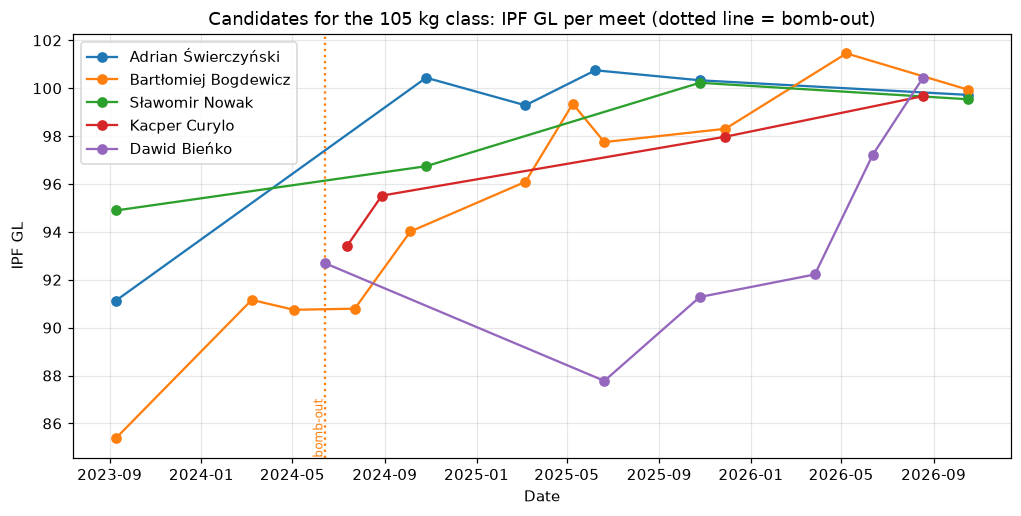

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in metrics.index:
    g = cand[cand["Name"] == name]
    valid = g[~g["BombOut"]]
    line, = ax.plot(valid["Date"], valid["GL"], marker="o", label=name)
    for date in g.loc[g["BombOut"], "Date"]:
        ax.axvline(date, color=line.get_color(), ls=":", lw=1.5)
        ax.annotate("bomb-out", (date, ax.get_ylim()[0]), color=line.get_color(), rotation=90,
                    va="bottom", ha="right", fontsize=8)
ax.set(title=f"Candidates for the {WEIGHT_CLASS} kg class: IPF GL per meet (dotted line = bomb-out)",
       xlabel="Date", ylabel="IPF GL")
ax.legend()
save(fig, "selection_gl_over_time")

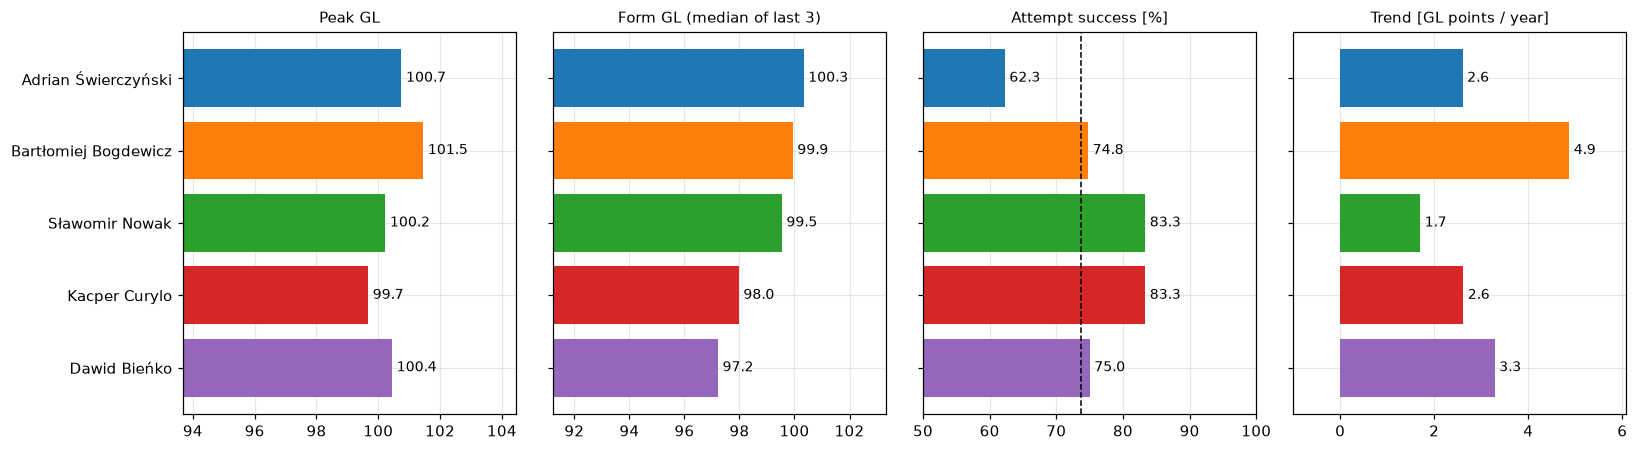

In [7]:
labels = {"peak GL": "Peak GL", "form GL": f"Form GL (median of last {FORM_LAST_N})",
          "attempt success %": "Attempt success [%]", "trend GL/year": "Trend [GL points / year]"}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
order = list(metrics.index)
for ax, col in zip(axes, metric_cols):
    values = metrics[col]
    bars = ax.barh(order[::-1], values[order[::-1]], color=[colors[order.index(n)] for n in order[::-1]])
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
    ax.set_title(labels[col], fontsize=10)
    lo = values.min()
    if col in ("peak GL", "form GL"):
        ax.set_xlim(lo - 6, values.max() + 3)
    elif col == "attempt success %":
        ax.axvline(100 * benchmark_success, color="black", ls="--", lw=1)
        ax.set_xlim(50, 100)
    else:
        ax.set_xlim(min(0, lo) - 1, values.max() * 1.25)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()
save(fig, "selection_metrics")

## 4. Head-to-head

Metrics compare lifters across different meets. Where candidates met at the same competition we can also
check who actually beat whom.

In [8]:
meet_cols = ["Date", "MeetName"]
shared = cand.groupby(meet_cols).filter(lambda m: m["Name"].nunique() >= 2)
h2h = shared.pivot_table(index=meet_cols, columns="Name", values="GL", aggfunc="first")
h2h = h2h[[n for n in metrics.index if n in h2h.columns]]
h2h.columns = [n.split()[-1] for n in h2h.columns]
h2h.index = [f"{d:%Y-%m-%d} {m[:45]}" for d, m in h2h.index]
print("GL at meets where at least two candidates competed (empty = did not compete or bombed out):")
display(h2h)

# A bomb-out loses to any lifter who posted a total at the same meet
wins = pd.DataFrame(0, index=metrics.index, columns=metrics.index)
for _, meet in shared.groupby(meet_cols):
    score = meet.set_index("Name")["GL"].fillna(-1)
    for a in score.index:
        for b in score.index:
            wins.loc[a, b] += int(score[a] > score[b])
wins.columns = [n.split()[-1] for n in wins.columns]
print("Head-to-head wins (row beat column, by GL at the same meet):")
wins

GL at meets where at least two candidates competed (empty = did not compete or bombed out):


,Świerczyński,Bogdewicz,Nowak,Curylo,Bieńko
2023-09-09 Mistrzostwa Polski Seniorów w Trójboju Siłowy,91.1,85.4,94.9,NaN,NaN
2024-06-14 Mistrzostwa Polski Juniorow i Weteranow w Tro,NaN,NaN,NaN,NaN,92.7
2024-10-26 Mistrzostwa Polski Seniorek i Seniorow w Troj,100.4,NaN,96.7,NaN,NaN
2025-03-07 Puchar Polski w Trójboju Siłowym Klasycznym,99.3,96.1,NaN,NaN,NaN
2025-06-20 Mistrzostwa Polski Juniorów i Masters w Trójb,NaN,97.8,NaN,NaN,87.8
2025-10-25 Mistrzostwa Polski w Trójboju Siłowym Klasycz,100.3,NaN,100.2,NaN,91.3
2025-11-28 European Juniors and Sub-Juniors Classic Cham,NaN,98.3,NaN,98.0,NaN
2026-08-18 World Sub-Junior and Junior Powerlifting Cham,NaN,NaN,NaN,99.7,100.4
2026-10-17 Mistrzostwa Polski w Trójboju Siłowym Klasycz,99.7,99.9,99.5,NaN,NaN


Head-to-head wins (row beat column, by GL at the same meet):


,Świerczyński,Bogdewicz,Nowak,Curylo,Bieńko
Adrian Świerczyński,0,2,3,0,1
Bartłomiej Bogdewicz,1,0,1,1,1
Sławomir Nowak,1,1,0,0,1
Kacper Curylo,0,0,0,0,0
Dawid Bieńko,0,1,0,1,0


## 5. Summary

The candidates' peaks lie within ~2 GL points of each other, so the peak alone cannot decide.
Form, attempt success and trend split the field in different directions; the recommendation and its
limitations are discussed in the report (`report/`) and the README.